# Inner Product Spaces

A computational companion to [Inner Product Spaces](https://fjhickernell.github.io/MATH332Fall2026/slides/10-inner-product-spaces.html): change the geometry with weights, split vectors into a projection and residual, and compute QR, regression, and finite function approximations.

The deck supplies the mathematical exposition. Predict the exact results before running each worked example. SymPy verifies exact identities; NumPy and SciPy illustrate floating-point computation. The core classroom path is Sections 1–4; Sections 5–7 extend it to weighted data, sensitivity, and functions.


## Running this notebook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fjhickernell/MATH332Fall2026/blob/main/notebooks/demonstrations/10-inner-product-spaces.ipynb)

Run all cells in order with the **qmcpy** kernel. The setup cell changes the environment only in Colab, where it installs the course's recorded `classlib` checkout. It leaves the working directory unchanged. Colab does not save edits to the course repository; save a copy in Drive to retain your experiments.


In [1]:
from pathlib import Path
import subprocess
import sys
import time

NOTEBOOK_START_TIME = time.perf_counter()

colab = "google.colab" in sys.modules
if colab:
    print("Setting up this course's recorded classlib; this may take a minute …")
    course_checkout = Path("/content/MATH332Fall2026")
    if not course_checkout.exists():
        subprocess.run(
            [
                "git", "clone", "--quiet", "--depth", "1",
                "https://github.com/fjhickernell/MATH332Fall2026.git",
                str(course_checkout),
            ],
            check=True,
        )
    subprocess.run(
        [
            "git", "-C", str(course_checkout),
            "-c", "submodule.classlib.url=https://github.com/fjhickernell/HickernellAcademicLib.git",
            "submodule", "update", "--init", "--recursive", "classlib",
        ],
        check=True,
    )
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", str(course_checkout / "classlib")],
        check=True,
    )
    print("Colab setup complete.")

In [2]:
import numpy as np
import sympy as sp
from sympy import Matrix
from scipy.linalg import solve_triangular
import matplotlib.pyplot as plt
import classlib as cl
from IPython.display import display, Markdown

%matplotlib inline
cl.nbviz.init(use_tex=False)
sp.init_printing()
np.set_printoptions(precision=7, suppress=True)
blue = cl.nbviz.TOL_BRIGHT["blue"]
red = cl.nbviz.TOL_BRIGHT["red"]
t = sp.symbols("t", real=True)

def show(label, value):
    display(Markdown(label))
    display(value)

def numeric(value):
    return np.array(value, dtype=float)


## 1. The inner product determines perpendicularity

The deck uses $\langle \boldsymbol u,\boldsymbol v\rangle_{\mathsf W}=\boldsymbol u^\top\mathsf W\boldsymbol v$ with $\mathsf W=\operatorname{diag}(1,4)$. Check that $(1,1)^\top$ and $(4,-1)^\top$ are perpendicular in this geometry even though their ordinary dot product is nonzero.

The weighted norm satisfies $\|\boldsymbol x\|_{\mathsf W}=\|\mathsf D\boldsymbol x\|_2$ for $\mathsf D=\operatorname{diag}(1,2)$. Thus scaling the coordinate axes turns weighted geometry into ordinary Euclidean geometry. Positive weights matter: a zero or negative weight would fail positive definiteness.


Ordinary dot product

Weighted inner product

Squared weighted norms of u and v

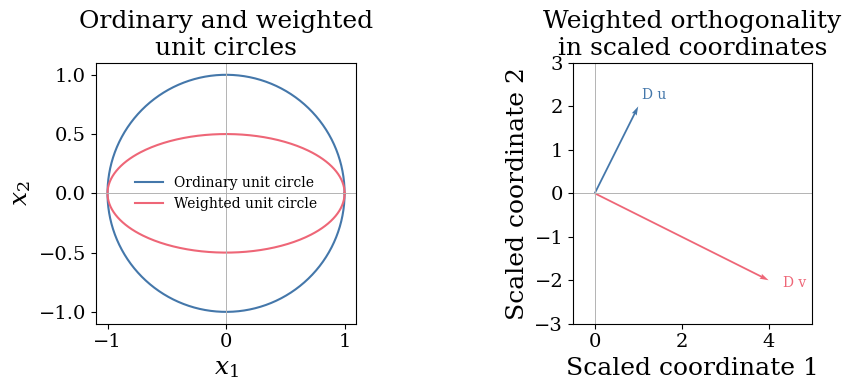

In [3]:
W = sp.diag(1, 4)
D = sp.diag(1, 2)
u, v = Matrix([1, 1]), Matrix([4, -1])
show("Ordinary dot product", (u.T*v)[0])
show("Weighted inner product", (u.T*W*v)[0])
show("Squared weighted norms of u and v", [(x.T*W*x)[0] for x in (u, v)])
assert W == D.T*D
assert (u.T*W*v)[0] == 0 and (u.T*v)[0] == 3
assert (D*u).dot(D*v) == 0

angle = np.linspace(0, 2*np.pi, 400)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(np.cos(angle), np.sin(angle), color=blue, label="Ordinary unit circle")
axes[0].plot(np.cos(angle), 0.5*np.sin(angle), color=red, label="Weighted unit circle")
axes[0].set(title="Ordinary and weighted\nunit circles", xlabel=r"$x_1$", ylabel=r"$x_2$")
for vec, label, color in [(D*u, "D u", blue), (D*v, "D v", red)]:
    xy = numeric(vec).ravel()
    axes[1].quiver(0, 0, *xy, angles="xy", scale_units="xy", scale=1, color=color)
    axes[1].text(*(1.08*xy), label, color=color)
axes[1].set(xlim=(-0.5, 5), ylim=(-3, 3), xlabel="Scaled coordinate 1", ylabel="Scaled coordinate 2", title="Weighted orthogonality\nin scaled coordinates")
for ax in axes:
    ax.axhline(0, color="0.7", lw=0.7)
    ax.axvline(0, color="0.7", lw=0.7)
    ax.set_aspect("equal", adjustable="box")
axes[0].legend(fontsize=10)
fig.tight_layout()
plt.show()


## 2. Projection leaves an orthogonal residual

Use the deck's plane $S=\operatorname{span}\{(1,1,0)^\top,(0,0,1)^\top\}$ and vector $\boldsymbol b=(3,1,2)^\top$. With orthonormal basis columns in $\mathsf Q$, the projection is $\boldsymbol p=\mathsf Q\mathsf Q^\top\boldsymbol b$.

Check membership, perpendicularity, and the Pythagorean identity. The distance to $S$ is the norm of the residual. Since $\mathsf Q$ is rectangular, $\mathsf Q^\top\mathsf Q$ and $\mathsf Q\mathsf Q^\top$ have different roles.


Projection matrix P

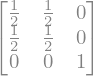

Projected vector and perpendicular residual

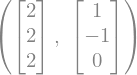

Distance to the plane

Exact checks confirm the orthogonal split and the closest-point identity.


In [4]:
Q_plane = Matrix([[1/sp.sqrt(2), 0], [1/sp.sqrt(2), 0], [0, 1]])
b_plane = Matrix([3, 1, 2])
P = sp.simplify(Q_plane*Q_plane.T)
p_plane = P*b_plane
r_plane = b_plane-p_plane
show("Projection matrix P", P)
show("Projected vector and perpendicular residual", (p_plane, r_plane))
show("Distance to the plane", sp.sqrt(r_plane.dot(r_plane)))
assert Q_plane.T*Q_plane == sp.eye(2)
assert P.T == P and P*P == P and P != sp.eye(3)
assert Q_plane.T*r_plane == sp.zeros(2, 1)
assert p_plane == Matrix([2, 2, 2])
assert r_plane.dot(r_plane) == 2
assert b_plane.dot(b_plane) == p_plane.dot(p_plane)+r_plane.dot(r_plane)

# Every other point in the plane is at least as far from b.
s, z = sp.symbols("s z", real=True)
w = Matrix([s, s, z])
assert sp.expand((b_plane-w).dot(b_plane-w)-r_plane.dot(r_plane)-(p_plane-w).dot(p_plane-w)) == 0
print("Exact checks confirm the orthogonal split and the closest-point identity.")


## 3. Gram–Schmidt records coordinates in a triangular factor

Start with the deck's columns $(1,1,0)^\top$ and $(1,0,1)^\top$. Remove the first direction from the second column, normalize, and construct $\mathsf R=\mathsf Q^\top\mathsf A$. Here $\mathsf R$ is the upper triangular QR factor.

This exact two-column calculation explains Gram–Schmidt. For routine numerical computation, `np.linalg.qr` uses a Householder-based implementation. Its column signs may differ while the reconstructed matrix and projection agree.


Second orthogonal remainder

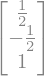

Q: orthonormal basis columns

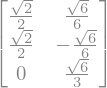

R: upper triangular coordinates

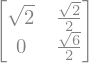

Numerical Q has shape (3, 2) and R has shape (2, 2)
Projection agrees even if QR column signs differ.


In [5]:
A_exact = Matrix([[1, 1], [1, 0], [0, 1]])
a1, a2 = A_exact[:, 0], A_exact[:, 1]
q1 = a1/sp.sqrt(a1.dot(a1))
w2 = sp.simplify(a2-q1.dot(a2)*q1)
q2 = sp.simplify(w2/sp.sqrt(w2.dot(w2)))
Q_exact = Matrix.hstack(q1, q2)
R_exact = sp.simplify(Q_exact.T*A_exact)
show("Second orthogonal remainder", w2)
show("Q: orthonormal basis columns", Q_exact)
show("R: upper triangular coordinates", R_exact)
assert sp.simplify(Q_exact.T*Q_exact) == sp.eye(2)
assert sp.simplify(Q_exact*R_exact) == A_exact
assert R_exact[1, 0] == 0 and R_exact[0, 0] > 0 and R_exact[1, 1] > 0

Q_numeric, R_numeric = np.linalg.qr(numeric(A_exact), mode="reduced")
assert np.allclose(Q_numeric@R_numeric, numeric(A_exact))
assert np.allclose(Q_numeric.T@Q_numeric, np.eye(2))
assert np.allclose(Q_numeric@Q_numeric.T, numeric(Q_exact*Q_exact.T))
print("Numerical Q has shape", Q_numeric.shape, "and R has shape", R_numeric.shape)
print("Projection agrees even if QR column signs differ.")


## 4. Fit a line by a triangular solve

For the observations $(-1,1),(0,0),(1,2)$, model $b\approx x_1+x_2t$. The columns of $\mathsf A$ are the sampled features $1$ and $t$; the fitted data vector lies in $\operatorname{col}(\mathsf A)$.

Compute reduced QR, then solve $\mathsf R\widehat{\boldsymbol x}=\mathsf Q^\top\boldsymbol b$. Check the normal equations without using them as the main numerical algorithm. The plotted errors are vertical response residuals, rather than perpendicular distances to the line in the graph.


Intercept and slope from QR

array([1. , 0.5])

Fitted values and residuals

(array([0.5, 1. , 1.5]), array([ 0.5, -1. ,  0.5]))

Normal-equation residual A.T @ residual

array([ 0., -0.])

Squared residual norm: 1.5


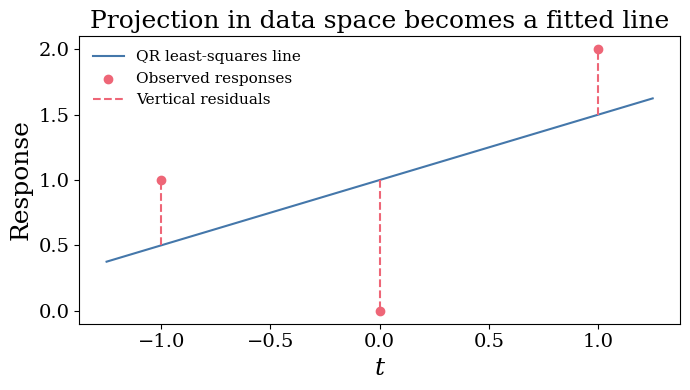

In [6]:
t_data = np.array([-1., 0., 1.])
b_data = np.array([1., 0., 2.])
A = np.column_stack([np.ones_like(t_data), t_data])
Q, R = np.linalg.qr(A, mode="reduced")
x_fit = solve_triangular(R, Q.T@b_data)
b_fit = A@x_fit
residual = b_data-b_fit
show("Intercept and slope from QR", x_fit)
show("Fitted values and residuals", (b_fit, residual))
show("Normal-equation residual A.T @ residual", A.T@residual)
print("Squared residual norm:", residual@residual)
assert np.allclose(x_fit, [1, 0.5])
assert np.allclose(A.T@residual, 0)
assert np.allclose(b_fit, Q@(Q.T@b_data))
assert np.isclose(residual@residual, 1.5)
x_normal = np.linalg.solve(A.T@A, A.T@b_data)
assert np.allclose(x_fit, x_normal)

plot_t = np.linspace(-1.25, 1.25, 200)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(plot_t, x_fit[0]+x_fit[1]*plot_t, color=blue, label="QR least-squares line")
ax.scatter(t_data, b_data, color=red, zorder=3, label="Observed responses")
ax.vlines(t_data, b_fit, b_data, color=red, linestyles="--", label="Vertical residuals")
ax.set(xlabel=r"$t$", ylabel="Response", title="Projection in data space becomes a fitted line")
ax.legend(fontsize=11)
fig.tight_layout()
plt.show()


## 5. Observation weights change the fitted vector

Give the middle observation four times the weight of either endpoint. Weighted least squares minimizes $\sum_i w_i((\mathsf A\boldsymbol x)_i-b_i)^2$. Apply QR to $\mathsf W^{1/2}\mathsf A$ and $\mathsf W^{1/2}\boldsymbol b$.

The resulting residual obeys $\mathsf A^\top\mathsf W\boldsymbol r=0$. It need not have zero ordinary dot product with each feature. These weights define the objective; they do not assert a statistical model for the data.


In [7]:
weights = np.array([1., 4., 1.])
sqrt_weights = np.sqrt(weights)
Aw = sqrt_weights[:, None]*A
bw = sqrt_weights*b_data
Qw, Rw = np.linalg.qr(Aw, mode="reduced")
x_weighted = solve_triangular(Rw, Qw.T@bw)
weighted_residual = b_data-A@x_weighted
show("Unweighted and weighted [intercept, slope]", np.vstack([x_fit, x_weighted]))
show("Weighted orthogonality A.T @ W @ residual", A.T@(weights*weighted_residual))
show("Ordinary A.T @ residual", A.T@weighted_residual)
assert np.allclose(x_weighted, [0.5, 0.5])
assert np.allclose(A.T@(weights*weighted_residual), 0)
assert not np.allclose(A.T@weighted_residual, 0)
assert np.dot(weights, weighted_residual**2) < np.dot(weights, residual**2)
print("The higher middle weight pulls the intercept toward its observed response 0.")


Unweighted and weighted [intercept, slope]

array([[1. , 0.5],
       [0.5, 0.5]])

Weighted orthogonality A.T @ W @ residual

array([-0.,  0.])

Ordinary A.T @ residual

array([1.5, 0. ])

The higher middle weight pulls the intercept toward its observed response 0.


## 6. Nearly dependent features: numerical error and data sensitivity

Let $\boldsymbol q_1,\boldsymbol q_2$ be orthonormal and set
\begin{equation*}
\mathsf A_\varepsilon=[\,\boldsymbol q_1\quad\boldsymbol q_1+\varepsilon\boldsymbol q_2\,].
\end{equation*}

The columns become nearly dependent as $\varepsilon$ shrinks. For the exact full-rank matrix, $\kappa_2(\mathsf A^\top\mathsf A)=\kappa_2(\mathsf A)^2$. Forming that product in floating point can lose the tiny difference that distinguishes the columns.

### Round-off in the normal equations

The table first uses exactly generated data with known coefficients $(1,2)^\top$. It reports relative coefficient and fitted-data errors for QR and normal equations. A singular normal-equation solve is an informative outcome, not evidence that the original matrix has dependent columns. Exact floating-point results vary by machine; this example does not establish that every normal-equation solve fails.


In [8]:
q1n = np.ones(4)/2
q2n = np.array([-3., -1., 1., 3.])/np.sqrt(20)
assert np.isclose(q1n@q2n, 0)
x_true = np.array([1., 2.])
rows = []
for epsilon in [1e-2, 1e-4, 1e-6, 1e-8]:
    design = np.column_stack([q1n, q1n+epsilon*q2n])
    response = design@x_true
    q, r = np.linalg.qr(design, mode="reduced")
    x_qr = solve_triangular(r, q.T@response)
    qr_coef = np.linalg.norm(x_qr-x_true)/np.linalg.norm(x_true)
    qr_fit = np.linalg.norm(design@x_qr-response)/np.linalg.norm(response)
    try:
        x_ne = np.linalg.solve(design.T@design, design.T@response)
        ne_coef = f"{np.linalg.norm(x_ne-x_true)/np.linalg.norm(x_true):.2e}"
        ne_fit = f"{np.linalg.norm(design@x_ne-response)/np.linalg.norm(response):.2e}"
    except np.linalg.LinAlgError:
        ne_coef, ne_fit = "singular solve", "—"
    kappa = np.linalg.cond(design)
    rows.append(f"| {epsilon:.0e} | {kappa:.2e} | {kappa**2:.2e} | {qr_coef:.2e} | {ne_coef} | {qr_fit:.2e} | {ne_fit} |")
    assert np.allclose(design@x_qr, response, rtol=1e-12, atol=1e-12)
display(Markdown("| epsilon | cond(A) | cond(A) squared | QR coefficient error | Normal coefficient error | QR fit error | Normal fit error |\n|---:|---:|---:|---:|---:|---:|---:|\n"+"\n".join(rows)))


| epsilon | cond(A) | cond(A) squared | QR coefficient error | Normal coefficient error | QR fit error | Normal fit error |
|---:|---:|---:|---:|---:|---:|---:|
| 1e-02 | 2.00e+02 | 4.00e+04 | 3.23e-15 | 2.81e-12 | 1.28e-16 | 1.48e-14 |
| 1e-04 | 2.00e+04 | 4.00e+08 | 2.22e-13 | 0.00e+00 | 0.00e+00 | 0.00e+00 |
| 1e-06 | 2.00e+06 | 4.00e+12 | 1.42e-10 | 2.81e-04 | 7.40e-17 | 1.48e-10 |
| 1e-08 | 2.00e+08 | 4.00e+16 | 1.72e-08 | singular solve | 7.40e-17 | — |

### Accurate computation cannot remove sensitivity in the data

Now keep $\varepsilon=10^{-6}$ and perturb the response by $\delta\boldsymbol b=10^{-7}\boldsymbol q_2$. The exact coefficient change is $(-0.1,0.1)^\top$ even though the data change has norm only $10^{-7}$.

QR avoids an unnecessary squaring of the condition number, but the original problem remains sensitive. Observe the large coefficient change alongside the small change in the fitted vector. SVD and regularization in the next deck explain how to diagnose and address this feature ambiguity.


In [9]:
epsilon = 1e-6
delta = 1e-7
design = np.column_stack([q1n, q1n+epsilon*q2n])
response = design@x_true
q, r = np.linalg.qr(design, mode="reduced")
x_before = solve_triangular(r, q.T@response)
x_after = solve_triangular(r, q.T@(response+delta*q2n))
coefficient_change = x_after-x_before
fit_change = design@coefficient_change
show("Coefficient change", coefficient_change)
print(f"Norm of data change: {delta:.2e}")
print(f"Norm of coefficient change: {np.linalg.norm(coefficient_change):.6f}")
print(f"Norm of fitted-vector change: {np.linalg.norm(fit_change):.2e}")
assert np.allclose(coefficient_change, [-delta/epsilon, delta/epsilon], rtol=1e-7, atol=1e-9)
assert np.allclose(fit_change, delta*q2n, rtol=1e-7, atol=1e-14)


Coefficient change

array([-0.1,  0.1])

Norm of data change: 1.00e-07
Norm of coefficient change: 0.141421
Norm of fitted-vector change: 1.00e-07


## 7. The same projection works for functions

On continuous real functions on $[0,1]$, use $\langle f,g\rangle=\int_0^1 f(t)g(t)\,dt$. The deck orthonormalizes $1,t$ to $q_1(t)=1$ and $q_2(t)=\sqrt{12}(t-1/2)$.

Project $f(t)=t^2$ onto their span. Verify the residual is orthogonal to both basis functions, the coefficients give $p(t)=t-1/6$, and the squared integral error is $1/180$. This continuous least-squares objective is different from fitting a finite table of sampled observations.


Integral Gram matrix

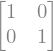

Orthonormal coefficients

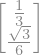

Best linear approximation and squared integral error

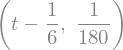

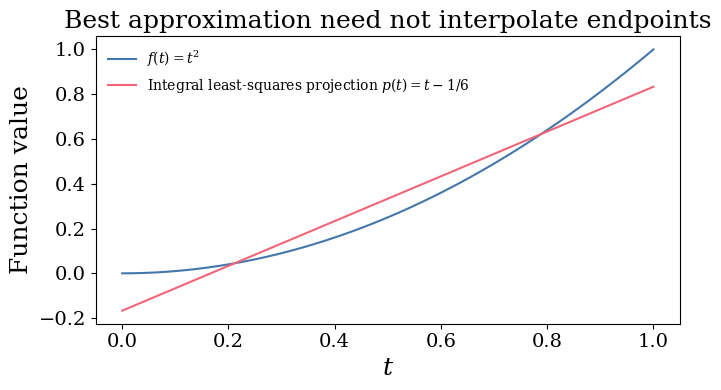

In [10]:
def function_inner(f, g):
    return sp.simplify(sp.integrate(sp.conjugate(f)*g, (t, 0, 1)))

function_basis = [sp.Integer(1), sp.sqrt(12)*(t-sp.Rational(1, 2))]
f = t**2
function_gram = Matrix([[function_inner(qi, qj) for qj in function_basis] for qi in function_basis])
function_coefficients = Matrix([function_inner(qj, f) for qj in function_basis])
p = sp.expand(sum(c*qj for c, qj in zip(function_coefficients, function_basis)))
function_residual = f-p
error_squared = function_inner(function_residual, function_residual)
show("Integral Gram matrix", function_gram)
show("Orthonormal coefficients", function_coefficients)
show("Best linear approximation and squared integral error", (p, error_squared))
assert function_gram == sp.eye(2)
assert p == t-sp.Rational(1, 6)
assert error_squared == sp.Rational(1, 180)
assert all(function_inner(qj, function_residual) == 0 for qj in function_basis)
assert function_inner(f, f) == sum(c**2 for c in function_coefficients)+error_squared

grid = np.linspace(0, 1, 400)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(grid, grid**2, color=blue, label=r"$f(t)=t^2$")
ax.plot(grid, grid-1/6, color=red, label=r"Integral least-squares projection $p(t)=t-1/6$")
ax.set(xlabel=r"$t$", ylabel="Function value", title="Best approximation need not interpolate endpoints")
ax.legend(fontsize=10)
fig.tight_layout()
plt.show()


### Complex conjugation fixes the coefficient convention

Match the deck: $\langle\boldsymbol u,\boldsymbol v\rangle=\boldsymbol u^*\boldsymbol v$ is conjugate linear in the first argument and linear in the second. NumPy's `np.vdot(u, v)` follows this convention; `np.dot(u, v)` does not conjugate.

The function helper above uses the same convention. For $q_k(t)=e^{2\pi i kt}$, the coefficient is $c_k=\langle q_k,f\rangle=\int_0^1 e^{-2\pi i kt}f(t)\,dt$.


In [11]:
u_complex = np.array([1j, 1])
v_complex = np.array([1, 1j])
show("vdot(u,u), the squared norm", np.vdot(u_complex, u_complex))
show("dot(u,u), without conjugation", np.dot(u_complex, u_complex))
show("vdot(u,v), the inner product", np.vdot(u_complex, v_complex))
assert np.vdot(u_complex, u_complex) == 2
assert np.dot(u_complex, u_complex) == 0
assert np.vdot(u_complex, v_complex) == 0
assert np.isclose(np.vdot(1j*u_complex, u_complex), -1j*np.vdot(u_complex, u_complex))
print("A nonzero complex vector cannot have zero squared inner-product norm.")


vdot(u,u), the squared norm

np.complex128(2+0j)

dot(u,u), without conjugation

np.complex128(0j)

vdot(u,v), the inner product

np.complex128(0j)

A nonzero complex vector cannot have zero squared inner-product norm.


### Fourier coordinates recover the deck's finite signal

Use $f(t)=2+3\cos(2\pi t)-\sin(4\pi t)$. Compute its normalized real coefficients and its complex coefficients for $k=-2,\ldots,2$. Check $c_{-k}=\overline{c_k}$.

The partial sums with frequency limits $N=0,1,2$ are orthogonal projections into nested finite-dimensional spaces. Here $N=2$ reconstructs the signal exactly because it has only those frequencies. This finite example makes no claim that an arbitrary Fourier series converges at every point.


Normalized real coefficients: constant, cosine k=1, sine k=2

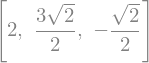

Complex coefficients, indexed by frequency

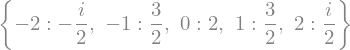

N=0: squared integral error = 5
N=1: squared integral error = 1/2
N=2: squared integral error = 0


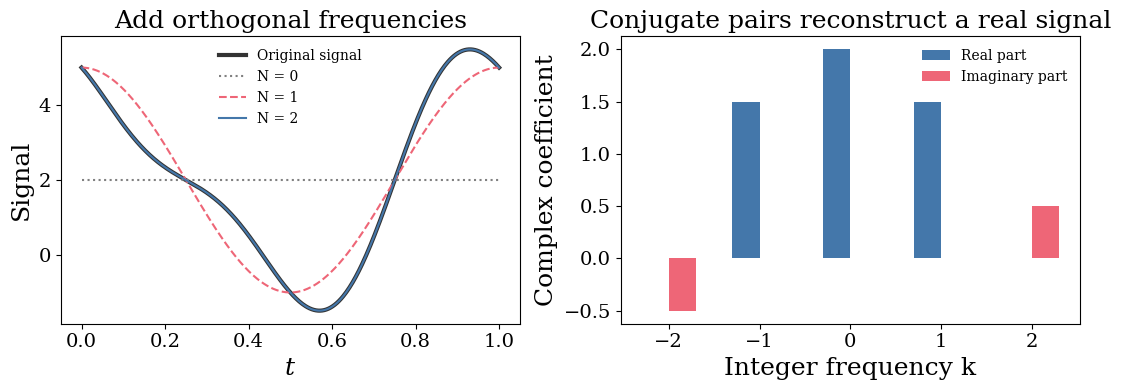

In [12]:
f_signal = 2+3*sp.cos(2*sp.pi*t)-sp.sin(4*sp.pi*t)
real_modes = [sp.Integer(1), sp.sqrt(2)*sp.cos(2*sp.pi*t), sp.sqrt(2)*sp.sin(4*sp.pi*t)]
real_coefficients = [function_inner(qj, f_signal) for qj in real_modes]
show("Normalized real coefficients: constant, cosine k=1, sine k=2", real_coefficients)
assert real_coefficients == [2, 3/sp.sqrt(2), -1/sp.sqrt(2)]

frequencies = np.arange(-2, 3)
complex_coefficients = {}
for k in frequencies:
    k = int(k)
    # Expand into real and imaginary trigonometric parts before exact integration.
    integrand = sp.expand_trig((sp.cos(2*sp.pi*k*t)-sp.I*sp.sin(2*sp.pi*k*t))*f_signal)
    complex_coefficients[k] = sp.simplify(sp.integrate(sp.expand(integrand), (t, 0, 1)))
show("Complex coefficients, indexed by frequency", complex_coefficients)
assert complex_coefficients == {-2: -sp.I/2, -1: sp.Rational(3, 2), 0: 2, 1: sp.Rational(3, 2), 2: sp.I/2}
assert all(complex_coefficients[-k] == sp.conjugate(complex_coefficients[k]) for k in range(3))
energy = function_inner(f_signal, f_signal)
assert energy == sum(sp.Abs(c)**2 for c in complex_coefficients.values())

signal_values = sp.lambdify(t, f_signal, "numpy")(grid)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(grid, signal_values, color="0.2", lw=3, label="Original signal")
errors = []
for N, color, style in [(0, "0.5", ":"), (1, red, "--"), (2, blue, "-")]:
    values = sum(complex(complex_coefficients[k])*np.exp(2j*np.pi*k*grid) for k in range(-N, N+1))
    assert np.max(np.abs(values.imag)) < 1e-12
    axes[0].plot(grid, values.real, color=color, linestyle=style, label=f"N = {N}")
    exact_error = sp.simplify(energy-sum(sp.Abs(complex_coefficients[k])**2 for k in range(-N, N+1)))
    errors.append(exact_error)
    print(f"N={N}: squared integral error = {exact_error}")
assert errors == [5, sp.Rational(1, 2), 0]
assert np.allclose(values.real, signal_values)
coef = np.array([complex(complex_coefficients[int(k)]) for k in frequencies])
axes[1].bar(frequencies-0.15, coef.real, width=0.3, color=blue, label="Real part")
axes[1].bar(frequencies+0.15, coef.imag, width=0.3, color=red, label="Imaginary part")
axes[0].set(xlabel=r"$t$", ylabel="Signal", title="Add orthogonal frequencies")
axes[1].set(xlabel="Integer frequency k", ylabel="Complex coefficient", xticks=frequencies, title="Conjugate pairs reconstruct a real signal")
for ax in axes:
    ax.legend(fontsize=10)
fig.tight_layout()
plt.show()


## Your experiments

1. In Section 1, replace $\mathsf W$ by $\operatorname{diag}(1,9)$. Find a nonzero vector weighted-perpendicular to $(1,1)^\top$ and check its ordinary dot product.
2. In Section 2, project $(1,0,3)^\top$ onto the same plane. Predict which component changes and check the distance.
3. Reverse the two columns in Section 3 and redo exact Gram–Schmidt. Compare the basis vectors, the triangular factor, and the projection matrices.
4. Fit the deck's practice data $(-1,0),(0,1),(1,1)$ using QR. Check both normal equations and the residual norm. Then change one observation weight and identify which orthogonality condition survives.
5. In Section 7, project $t^3$ onto $\operatorname{span}\{1,t\}$. Verify the integral residual conditions; compare the result with a line fitted to three sampled values of $t^3$.
6. Replace the Fourier signal by $1+2\cos(6\pi t)$. Extend the frequency range before reconstructing it. Predict its complex coefficients and squared error when only $|k|\le2$ is retained.

Return to the deck for the general projection and QR arguments. [Special Topics](https://fjhickernell.github.io/MATH332Fall2026/slides/11-special-topics.html) develops SVD, rank deficiency, and sensitive regression features.


In [13]:
notebook_elapsed = time.perf_counter() - NOTEBOOK_START_TIME
notebook_minutes, notebook_seconds = divmod(notebook_elapsed, 60)
print(
    "Total execution time for this notebook is "
    f"{int(notebook_minutes)} min {notebook_seconds:.1f} sec."
)

Total execution time for this notebook is 0 min 6.8 sec.
